# v5 — capital efficiency & margin realism (returns per dollar of equity)

The backtest booked returns **per dollar of pair notional** and implicitly assumed $1 of notional
per $1 of capital. That assumption is a *margin model*, and v5 makes it explicit. For a
delta-neutral pair, spot must be paid in full and the perp posts margin `N/k` at perp leverage `k`:

$$N + N/k = E \;\Rightarrow\; \text{deploy ratio } d = N/E = \frac{k}{k+1}$$

($100k at k=4 → $80k spot + $20k perp margin → an 80/80 book.) Under **Portfolio Margin** (one
account, the spot itself collateralizes the perp — Binance PM) the reserved margin vanishes:
**d = 1.0**, which is exactly what v0–v4 assumed. So the questions v5 answers: (1) what does each
margin setup actually earn per dollar of equity, (2) is the d=1.0 setup **safe** (how far from
liquidation), and (3) is going beyond 1× (borrowed spot) worth it? Mechanics (uniMMR, tiers,
haircuts) are cited in `../leverage_mechanics.md`.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'
import sys; from pathlib import Path
_p = Path.cwd().resolve()
ROOT = next((q for q in [_p, *_p.parents] if (q/'pyproject.toml').exists()), _p)
sys.path[:0] = [str(ROOT)]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import research.funding_carry.lab as H
from src.common import config as cfg
from src.data import query
plt.rcParams.update({'figure.figsize':(14,3.8),'axes.grid':True,'grid.alpha':0.25,
                     'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
NAVY,TEAL,AMBER,RED,GREY='#1f3a5f','#2a9d8f','#e0a32e','#c1121f','0.6'
COSTS=cfg.load_config('strategies/funding_carry/v5.yaml')['costs']
MG=cfg.load_config('strategies/funding_carry/v5.yaml')['margin']
maj,non=H.universe(); P=H.load_panels(maj+non); didx=P['didx']
SPECS=[{'name':'funding_vol','window':30},{'name':'neg_freq','window':30},{'name':'basis','window':30}]
VETO=[{'feature':'funding_vol','direction':'max','cap':0.75},{'feature':'neg_freq','direction':'max','cap':0.40},{'feature':'basis','direction':'max','cap':0.01}]
sh=H.evaluate_select(P,7,0.08,0.02,None,None,COSTS,feature_specs=SPECS,veto_rules=VETO,size_kind='inv_basis_vol',band=0.5,warmup_days=30)
state=H.overlay_state(H.drawdown(sh['net'].dropna()),0.15,0.50,252,True).reindex(didx).fillna(1.0)
W=sh['W'].mul(state,axis=0); pos=W.shift(1).fillna(0.0)
net=(sh['net']*state.reindex(sh['net'].index).fillna(1.0)).dropna()     # v4/v5 net per $1 NOTIONAL
print('v4/v5 book loaded | net per notional:', f"{net.mean()*365:+.1%}/yr")

v4/v5 book loaded | net per notional: +10.0%/yr


## 1. What each margin setup earns per dollar of equity

Same strategy, same Sharpe — the margin mode only sets **how much of your equity is working**.
This is the honest ROE table (the engine now books exactly this via the `margin` config block):

                                               deploy d  ROE %/yr  Sharpe  maxDD %
setup                                                                             
isolated k=1 (naive 50/50)                        0.500       5.0    6.71     -0.4
isolated k=2                                      0.667       6.7    6.71     -0.6
isolated k=4 (owner example: 80/80)               0.800       8.0    6.71     -0.7
isolated k=10                                     0.909       9.1    6.71     -0.8
PORTFOLIO MARGIN (100/100) = v0-v4 assumption     1.000      10.0    6.71     -0.9


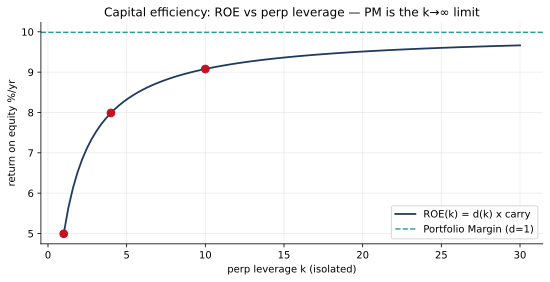

In [2]:
rows=[]
for k,d,lab_ in [(1,0.5,'isolated k=1 (naive 50/50)'),(2,2/3,'isolated k=2'),(4,0.8,'isolated k=4 (owner example: 80/80)'),
                 (10,10/11,'isolated k=10'),(None,1.0,'PORTFOLIO MARGIN (100/100) = v0-v4 assumption')]:
    r=net*d; e=(1+r).cumprod(); dd=(e/e.cummax()-1).min()
    rows.append({'setup':lab_,'deploy d':round(d,3),'ROE %/yr':round(r.mean()*365*100,1),
                 'Sharpe':round(r.mean()/r.std()*np.sqrt(365),2),'maxDD %':round(dd*100,1)})
T=pd.DataFrame(rows).set_index('setup'); print(T.to_string())
fig,ax=plt.subplots(figsize=(9,4))
ks=np.linspace(1,30,100); ax.plot(ks, net.mean()*365*100*ks/(ks+1), color=NAVY, lw=1.8, label='ROE(k) = d(k) x carry')
ax.axhline(net.mean()*365*100, color=TEAL, ls='--', lw=1.4, label='Portfolio Margin (d=1)')
for k,d in [(1,0.5),(4,0.8),(10,10/11)]: ax.scatter([k],[net.mean()*365*100*d],s=60,color=RED,zorder=5)
ax.set_xlabel('perp leverage k (isolated)'); ax.set_ylabel('return on equity %/yr')
ax.set_title('Capital efficiency: ROE vs perp leverage — PM is the k→∞ limit'); ax.legend()
plt.show()

## 2. Is the Portfolio-Margin setup safe? — the daily uniMMR path

Under PM, liquidation fires at **uniMMR ≤ 1.05** where `uniMMR = adjusted equity / maintenance
margin`. Adjusted equity applies **collateral haircuts** to the spot (majors ~0.95; alts far lower —
we stress 0.7/0.5/0.3), plus the transient leak on up-moves (spot counted at the haircut, perp loss
at par). Maintenance margin uses per-class MMRs (majors 0.4%, mids 1%, alts 2% — conservative
tier-1 values). The result: **worst-day uniMMR ≥ ~11 even at a 30% alt collateral ratio** — the
delta-neutral book is structurally far from liquidation, because price moves net out and MM is tiny.

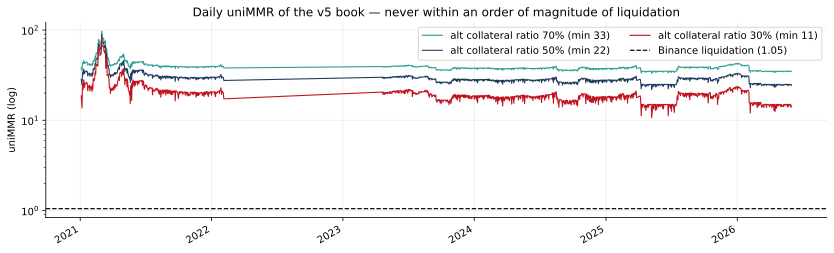

         min   p01   med
alt_cr                  
0.7     33.1  34.4  38.2
0.5     21.9  23.9  28.6
0.3     10.7  13.5  18.9


In [3]:
cols=pos.columns
MAJ={'btcusdt','ethusdt'}; MID={'bnbusdt','solusdt','xrpusdt','adausdt','dogeusdt','ltcusdt','linkusdt','dotusdt'}
mmr=np.array([MG['mmr_overrides'].get(s,MG['mmr_default']) for s in cols])
held=[s for s in cols if (pos[s]>0).any()]
rets={}; highs={}
for s in held:
    b=query.get('perps','binance',s,'bars',timeframe='1h',columns=['close','high'])
    if b.empty: continue
    c=b['close'].resample('1D').last(); rets[s]=c.pct_change().reindex(didx)
    highs[s]=(b['high'].resample('1D').max()/c.shift(1)-1).reindex(didx)
RET=pd.DataFrame(rets).reindex(columns=cols); HI=pd.DataFrame(highs).reindex(columns=cols)
fig,ax=plt.subplots(figsize=(14,4))
summ={}
for alt_cr,c in [(0.7,TEAL),(0.5,NAVY),(0.3,RED)]:
    cr=np.array([0.95 if s in MAJ else (0.80 if s in MID else alt_cr) for s in cols])
    adj=(pos*cr).sum(axis=1)+(1-pos.sum(axis=1)).clip(lower=0)
    leak=(pos*(1-cr)*RET.fillna(0)).sum(axis=1).clip(lower=0)
    uni=((adj-leak)/(pos*mmr).sum(axis=1).replace(0,np.nan)).dropna()
    uni.plot(ax=ax,color=c,lw=1.1,label=f'alt collateral ratio {alt_cr:.0%} (min {uni.min():.0f})')
    summ[alt_cr]=dict(min=round(uni.min(),1),p01=round(uni.quantile(0.01),1),med=round(uni.median(),1))
ax.axhline(1.05,color='k',lw=1.2,ls='--',label='Binance liquidation (1.05)')
ax.set_yscale('log'); ax.set_ylabel('uniMMR (log)'); ax.legend(ncol=2)
ax.set_title('Daily uniMMR of the v5 book — never within an order of magnitude of liquidation')
plt.show(); print(pd.DataFrame(summ).T.rename_axis('alt_cr').to_string())

## 3. Why not isolated margin? — per-name liquidation events

In isolated mode each short perp must survive **alone** on its `1/k` margin buffer: if an alt perp
rallies more than ~`1/k` intraday before you top up, the short is force-liquidated (clearance fee
~0.5–1% of notional, plus you're left naked-long spot until re-hedged). Counting actual breaches
across held name-days:

   buffer  close-to-close breaches  intraday-high breaches  est. drag %/yr
k                                                                         
2     50%                      154                     390            0.84
4     25%                      868                    2147            4.64
6     17%                     2326                    5739           12.40
10    10%                     8086                   18227           39.37
20     5%                    26864                   57992          125.27


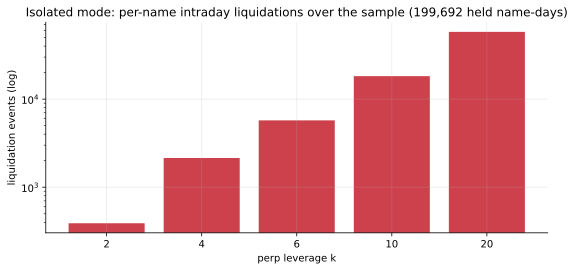

In [4]:
heldmask=pos>0; nd=int(heldmask.sum().sum())
rows=[]
for k in (2,4,6,10,20):
    buf=1.0/k
    cc=int(((RET>buf)&heldmask).sum().sum()); ih=int(((HI>buf)&heldmask).sum().sum())
    # rough cost drag: each event ~1.5% of that name's notional (fee+slippage+rehedge), weight ~ avg held weight
    avg_w=float(pos[pos>0].stack().mean()); yrs=len(net)/365
    drag=ih*avg_w*0.015/yrs
    rows.append({'k':k,'buffer':f'{buf:.0%}','close-to-close breaches':cc,'intraday-high breaches':ih,
                 'est. drag %/yr':round(drag*100,2)})
print(pd.DataFrame(rows).set_index('k').to_string())
fig,ax=plt.subplots(figsize=(9,3.8))
ks=[r['k'] for r in rows]; ih=[r['intraday-high breaches'] for r in rows]
ax.bar([str(k) for k in ks], ih, color=RED, alpha=0.8)
ax.set_yscale('log'); ax.set_xlabel('perp leverage k'); ax.set_ylabel('liquidation events (log)')
ax.set_title(f'Isolated mode: per-name intraday liquidations over the sample ({nd:,} held name-days)')
plt.show()

## 4. Beyond 1×? Borrowed-spot leverage isn't worth it

The only way to run **more notional than equity** is borrowing USDT (~9–11%/yr, floating) to buy
extra spot — the perp side never pays interest. Since the strategy nets ~10%/yr, borrowing at
~10% to earn ~10% adds risk for nothing; it only pays in hot-carry years (2021: +22% per extra
turn of leverage; 2022/23/25: negative). And the borrow rate itself spikes exactly when carry is
hot, eroding the good years too.

In [5]:
print('ROE on equity at borrowed leverage L (v5 book):')
rows=[]
for L in (1,2,3,5):
    for b in (0.05,0.10,0.15):
        r=L*net-(L-1)*b/365; e=(1+r).cumprod(); dd=(e/e.cummax()-1).min()
        rows.append({'L':L,'borrow':f'{b:.0%}','ROE %':round(r.mean()*365*100,1),
                     'Sharpe':round(r.mean()/r.std()*np.sqrt(365),2),'maxDD %':round(dd*100,1)})
print(pd.DataFrame(rows).pivot(index='L',columns='borrow',values='ROE %').to_string())
print('\nby-year net vs a 10% borrow hurdle (marginal ROE per extra turn of L):')
for y in range(2021,2027):
    m=net.index.year==y
    if m.sum()<10: continue
    print(f"  {y}: net {net[m].mean()*365*100:+5.1f}%  -> marginal {100*(net[m].mean()*365-0.10):+5.1f}%")

ROE on equity at borrowed leverage L (v5 book):
borrow   10%   15%    5%
L                       
1       10.0  10.0  10.0
2       10.0   5.0  15.0
3       10.0  -0.0  20.0
5        9.9 -10.1  29.9

by-year net vs a 10% borrow hurdle (marginal ROE per extra turn of L):
  2021: net +32.3%  -> marginal +22.3%
  2022: net  +0.2%  -> marginal  -9.8%
  2023: net  +5.5%  -> marginal  -4.5%
  2024: net +13.4%  -> marginal  +3.4%
  2025: net  +2.3%  -> marginal  -7.7%
  2026: net  +5.4%  -> marginal  -4.6%


## Conclusions — v5 shipped as the explicit margin model

- **Returns are now booked per dollar of equity** (the honest basis), with the margin setup declared
  in config: `margin.mode: portfolio` → deploy 1.0; `isolated, perp_leverage k` → deploy k/(k+1)
  (verified end-to-end: isolated k=4 books exactly 0.8× the PM returns, Sharpe unchanged).
- **The Portfolio-Margin setup (what v0–v4 silently assumed) is validated**: daily uniMMR ≥ ~25 with
  our haircut map, ≥ ~11 even valuing all alt spot at 30% collateral — an order of magnitude above
  Binance's 1.05 liquidation line, because the two legs net and maintenance margin is tiny.
- **PM dominates isolated margin on both axes**: more capital deployed (1.00 vs 0.80 at k=4) and no
  per-name liquidation events (isolated k=4 would have suffered ~2,100 intraday breaches; alts do
  +25% days). The owner's k=4 construction works, but one-venue PM is strictly better.
- **Don't scale beyond 1×**: borrowed-spot leverage costs ≈ the carry itself; only hot-carry regimes
  justify it, and the borrow rate co-moves with funding. Revisit only if carry re-rates far above
  borrow.
- Caveats: collateral ratios / MMR tiers are conservative approximations of Binance's live tables
  (pull the API before deployment); uniMMR sim ignores intra-day paths (daily granularity); the
  clearance-fee/naked-leg cost of an isolated liquidation is estimated, not booked.